# KBS Risiko Readmisi 30 Hari Pasien Diabetes (pytholog)

**Kasus:** menilai risiko seorang pasien diabetes dirawat ulang dalam 30 hari setelah pulang, dari informasi yang sudah ada saat pasien pulang.
**Data:** UCI *Diabetes 130-US Hospitals for Years 1999-2008* (CC BY 4.0). Sitasi: Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). https://doi.org/10.24432/C5230J

Notebook ini memuat kasus, semantic network, aturan IF-THEN, kode pytholog, query, dan keluaran. Angka ambang adalah usulan yang boleh diubah di bagian parameter.

| Keluaran sistem | Fitur yang dipakai | Pertanyaan yang dijawab |
|---|---|---|
| **Tingkat risiko** (tinggi / sedang / rendah) | lama rawat, jenis masuk, jumlah diagnosis, riwayat rawat inap, riwayat UGD, usia, tujuan pulang | Seberapa besar kemungkinan pasien ini dirawat ulang dalam 30 hari? |

> **Batas:** alat bantu belajar, bukan pengganti penilaian klinis.

## 1. Sumber pengetahuan

| Sumber | Dipakai untuk | Status |
|---|---|---|
| **Indeks LACE** (van Walraven dkk., CMAJ 2010): lama rawat (**L**), masuk akut (**A**), komorbiditas (**C**), kunjungan UGD (**E**) | Memilih indikator risiko: lama rawat, jenis masuk darurat, kunjungan UGD, jumlah diagnosis | Aturan skor LACE mengacu pada dokumentasi paket R *cliot*; cocokkan dengan artikel aslinya sebelum dikutip |
| **Temuan pada data latih** (bagian 3 dan 9) | Indikator tambahan: jumlah rawat inap sebelumnya, tujuan pulang ke fasilitas, usia lanjut | Ini temuan data ini, **bukan pedoman klinis** |

**Penyesuaian terhadap LACE** yang harus ditulis jujur di laporan:
- Data tidak punya skor Charlson. `number_diagnoses` dipakai sebagai **pendekatan** komorbiditas.
- `number_emergency` dipakai sebagai kunjungan UGD sebelumnya. Periode pencatatannya perlu dicek di dokumentasi UCI dan mungkin tidak sama dengan "6 bulan" pada LACE.
- Aturan di sini **bukan skor LACE bertingkat**; hanya memakai komponennya sebagai indikator ya/tidak.

## 2. Parameter ambang (boleh diubah)

In [1]:
RANDOM_STATE = 42

AMBANG = {
    "rawat_lama_hari": 7,          # LACE: lama rawat >= 7 hari mendapat poin besar
    "ugd_berulang": 2,             # kunjungan UGD sebelumnya >= 2
    "banyak_diagnosis": 9,         # pendekatan komorbiditas (persentil ke-75 data = 9)
    "pernah_inap": 1,              # rawat inap sebelumnya >= 1
    "inap_berulang": 2,            # rawat inap sebelumnya >= 2
    "usia_lansia": 70,
}
KODE_MASUK_DARURAT = [1, 2, 7]                 # Emergency, Urgent, Trauma Center (IDS_mapping.csv)
KODE_PULANG_FASILITAS = [2, 3, 4, 5, 22, 23, 24, 28]  # dipindah ke fasilitas lain (IDS_mapping.csv)

## 3. Data: muat, bersihkan seperlunya, bagi latih dan uji

In [2]:
!pip install -q pytholog

In [3]:
import glob, os, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

pd.set_option("display.width", 180)

def cari_data():
    for akar in [".", "..", "/content"]:
        f = glob.glob(os.path.join(akar, "**", "diabetic_data.csv"), recursive=True)
        if f:
            return f[0]
    url = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"
    try:
        os.makedirs("data_uci", exist_ok=True)
        z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        z.extractall("data_uci")
        return os.path.join("data_uci", "diabetic_data.csv")
    except Exception as e:
        raise SystemExit(f"Data tidak ditemukan dan unduhan gagal: {e}\nUnduh dari UCI lalu taruh diabetic_data.csv di folder kerja.")

df = pd.read_csv(cari_data(), keep_default_na=False).replace("?", np.nan)
awal = len(df)

# pembersihan minimal (rincian lengkap ada di notebook praproses)
df = df.dropna(subset=["diag_1"])
df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]      # meninggal / hospice
df = df[df["gender"] != "Unknown/Invalid"]
df = df.sort_values("encounter_id").drop_duplicates("patient_nbr", keep="first")  # satu kunjungan per pasien

df["asli"] = np.where(df["readmitted"] == "<30", "Ya", "Tidak")   # dirawat ulang < 30 hari?
df["age_mid"] = df["age"].map({f"[{a}-{a+10})": a + 5 for a in range(0, 100, 10)})

latih, uji = train_test_split(df, test_size=0.2, stratify=df["asli"], random_state=RANDOM_STATE)
print(f"{awal} kunjungan -> {len(df)} pasien | latih {len(latih)} | uji {len(uji)}")
print("Proporsi dirawat ulang < 30 hari (latih):", round((latih['asli'] == 'Ya').mean(), 3))

101766 kunjungan -> 69979 pasien | latih 55983 | uji 13996
Proporsi dirawat ulang < 30 hari (latih): 0.09


## 4. Semantic network

Atribut pasien (kiri) diubah menjadi indikator memakai ambang; indikator masuk ke aturan IF-THEN (T = menuju risiko tinggi, S = menuju risiko sedang); aturan menghasilkan tingkat risiko (kanan).
Aturan bertanda **DAN** menerima dua indikator yang harus terpenuhi bersama.

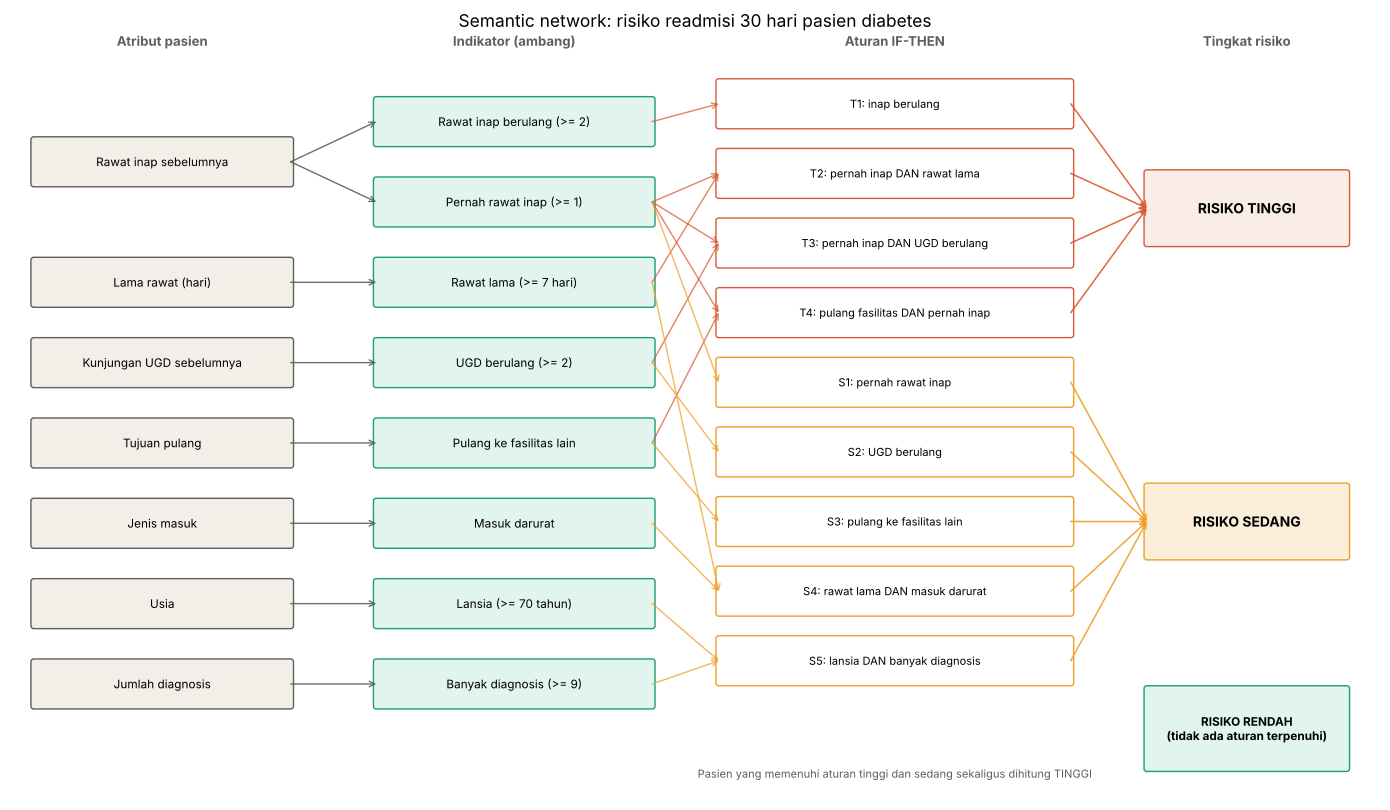

In [4]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 8.2))
ax.set_xlim(0, 14.4); ax.set_ylim(0, 8.6); ax.axis("off")

def kotak(x, y, teks, w, h=0.5, fc="#F1EFE8", ec="#5F5E5A", fs=8.5, bold=False):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.03", fc=fc, ec=ec, lw=1))
    ax.text(x, y, teks, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else "normal")

def garis(x1, y1, x2, y2, warna, lw=1.1, panah=True, alpha=0.9):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->" if panah else "-", color=warna, lw=lw, alpha=alpha, shrinkA=0, shrinkB=0))

X_ATR, X_IND, X_ATURAN, X_RISIKO = 1.6, 5.3, 9.3, 13.0
W_ATR, W_IND, W_ATURAN, W_RISIKO = 2.7, 2.9, 3.7, 2.1
MERAH, ORANYE, HIJAU = "#D85A30", "#EF9F27", "#1D9E75"

# --- indikator (urut agar garis tidak banyak bersilangan)
ind_y = {"inap2": 7.6, "inap": 6.7, "lama": 5.8, "ugd": 4.9, "pulang": 4.0, "masuk": 3.1, "lansia": 2.2, "diag": 1.3}
ind_teks = {"inap2": "Rawat inap berulang (>= 2)", "inap": "Pernah rawat inap (>= 1)", "lama": "Rawat lama (>= 7 hari)",
            "ugd": "UGD berulang (>= 2)", "pulang": "Pulang ke fasilitas lain", "masuk": "Masuk darurat",
            "lansia": "Lansia (>= 70 tahun)", "diag": "Banyak diagnosis (>= 9)"}
for k, y in ind_y.items():
    kotak(X_IND, y, ind_teks[k], W_IND, fc="#E1F5EE", ec=HIJAU)

# --- atribut -> indikator
atr = [("Rawat inap sebelumnya", (ind_y["inap2"] + ind_y["inap"]) / 2, ["inap2", "inap"]),
       ("Lama rawat (hari)", ind_y["lama"], ["lama"]),
       ("Kunjungan UGD sebelumnya", ind_y["ugd"], ["ugd"]),
       ("Tujuan pulang", ind_y["pulang"], ["pulang"]),
       ("Jenis masuk", ind_y["masuk"], ["masuk"]),
       ("Usia", ind_y["lansia"], ["lansia"]),
       ("Jumlah diagnosis", ind_y["diag"], ["diag"])]
for teks, y, tujuan in atr:
    kotak(X_ATR, y, teks, W_ATR)
    for k in tujuan:
        garis(X_ATR + W_ATR/2, y, X_IND - W_IND/2, ind_y[k], "#5F5E5A", lw=1.0)

# --- aturan
aturan_def = [
    ("T1", "inap berulang", ["inap2"], MERAH),
    ("T2", "pernah inap DAN rawat lama", ["inap", "lama"], MERAH),
    ("T3", "pernah inap DAN UGD berulang", ["inap", "ugd"], MERAH),
    ("T4", "pulang fasilitas DAN pernah inap", ["pulang", "inap"], MERAH),
    ("S1", "pernah rawat inap", ["inap"], ORANYE),
    ("S2", "UGD berulang", ["ugd"], ORANYE),
    ("S3", "pulang ke fasilitas lain", ["pulang"], ORANYE),
    ("S4", "rawat lama DAN masuk darurat", ["lama", "masuk"], ORANYE),
    ("S5", "lansia DAN banyak diagnosis", ["lansia", "diag"], ORANYE),
]
y_aturan = {}
for i, (kode, teks, sumber, warna) in enumerate(aturan_def):
    y = 7.8 - i * 0.78
    y_aturan[kode] = y
    kotak(X_ATURAN, y, f"{kode}: {teks}", W_ATURAN, h=0.5, fc="white", ec=warna, fs=8)
    for s in sumber:
        garis(X_IND + W_IND/2, ind_y[s], X_ATURAN - W_ATURAN/2, y, warna, lw=1.0, alpha=0.75)

# --- tingkat risiko
y_tinggi = np.mean([y_aturan[k] for k in ["T1", "T2", "T3", "T4"]])
y_sedang = np.mean([y_aturan[k] for k in ["S1", "S2", "S3", "S4", "S5"]])
kotak(X_RISIKO, y_tinggi, "RISIKO TINGGI", W_RISIKO, h=0.8, fc="#FAECE7", ec=MERAH, fs=10, bold=True)
kotak(X_RISIKO, y_sedang, "RISIKO SEDANG", W_RISIKO, h=0.8, fc="#FAEEDA", ec=ORANYE, fs=10, bold=True)
kotak(X_RISIKO, 0.8, "RISIKO RENDAH\n(tidak ada aturan terpenuhi)", W_RISIKO, h=0.9, fc="#E1F5EE", ec=HIJAU, fs=8.5, bold=True)
for k in ["T1", "T2", "T3", "T4"]:
    garis(X_ATURAN + W_ATURAN/2, y_aturan[k], X_RISIKO - W_RISIKO/2, y_tinggi, MERAH, lw=1.1)
for k in ["S1", "S2", "S3", "S4", "S5"]:
    garis(X_ATURAN + W_ATURAN/2, y_aturan[k], X_RISIKO - W_RISIKO/2, y_sedang, ORANYE, lw=1.1)

for x, teks in [(X_ATR, "Atribut pasien"), (X_IND, "Indikator (ambang)"), (X_ATURAN, "Aturan IF-THEN"), (X_RISIKO, "Tingkat risiko")]:
    ax.text(x, 8.45, teks, ha="center", fontsize=9.5, color="#5F5E5A", fontweight="bold")
ax.text(X_ATURAN, 0.25, "Pasien yang memenuhi aturan tinggi dan sedang sekaligus dihitung TINGGI", ha="center", fontsize=8, color="#5F5E5A")
ax.set_title("Semantic network: risiko readmisi 30 hari pasien diabetes", fontsize=12.5, pad=4)
plt.tight_layout()
plt.savefig("semantic_network_readmisi.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Aturan IF-THEN

Format Prolog: `kesimpulan(X) :- syarat(X)` dibaca "X berkesimpulan JIKA X bersyarat". Koma (`,`) = DAN. Dua aturan berkepala sama = ATAU.

| No | Aturan (IF ... THEN ...) | Dasar |
|---|---|---|
| T1 | IF rawat inap berulang (>= 2) THEN risiko **tinggi** | Temuan data: readmisi 20,5% vs 8,6% |
| T2 | IF pernah rawat inap DAN rawat lama THEN **tinggi** | Temuan data + LACE (L) |
| T3 | IF pernah rawat inap DAN UGD berulang THEN **tinggi** | Temuan data + LACE (E) |
| T4 | IF pulang ke fasilitas lain DAN pernah rawat inap THEN **tinggi** | Temuan data |
| S1 | IF pernah rawat inap THEN **sedang** | Temuan data |
| S2 | IF UGD berulang THEN **sedang** | LACE (E) |
| S3 | IF pulang ke fasilitas lain THEN **sedang** | Temuan data |
| S4 | IF rawat lama DAN masuk darurat THEN **sedang** | LACE (L, A) |
| S5 | IF lansia DAN banyak diagnosis THEN **sedang** | Temuan data + LACE (C, pendekatan) |
| R | Selain itu: **rendah** (tanpa aturan sendiri) | |

Pasien yang memenuhi aturan tinggi sekaligus sedang dihitung **tinggi** (prioritas diatur pada bagian hasil).

In [5]:
import pytholog as pl

# 1. FAKTA: ambang diterapkan pada angka di data -> pernyataan benar/salah per pasien
def fakta_dari(d):
    f = []
    a = AMBANG
    kondisi = {
        "rawat_lama":      d["time_in_hospital"] >= a["rawat_lama_hari"],
        "masuk_darurat":   d["admission_type_id"].isin(KODE_MASUK_DARURAT),
        "ugd_berulang":    d["number_emergency"] >= a["ugd_berulang"],
        "banyak_diagnosis":d["number_diagnoses"] >= a["banyak_diagnosis"],
        "pernah_inap":     d["number_inpatient"] >= a["pernah_inap"],
        "inap_berulang":   d["number_inpatient"] >= a["inap_berulang"],
        "lansia":          d["age_mid"] >= a["usia_lansia"],
        "pulang_fasilitas":d["discharge_disposition_id"].isin(KODE_PULANG_FASILITAS),
    }
    for nama, mask in kondisi.items():
        for pid in d.loc[mask, "patient_nbr"]:
            f.append(f"{nama}(p{pid})")
    return f, kondisi

# 2. ATURAN
aturan = [
    "tinggi(X) :- inap_berulang(X)",
    "tinggi(X) :- pernah_inap(X), rawat_lama(X)",
    "tinggi(X) :- pernah_inap(X), ugd_berulang(X)",
    "tinggi(X) :- pulang_fasilitas(X), pernah_inap(X)",
    "sedang(X) :- pernah_inap(X)",
    "sedang(X) :- ugd_berulang(X)",
    "sedang(X) :- pulang_fasilitas(X)",
    "sedang(X) :- rawat_lama(X), masuk_darurat(X)",
    "sedang(X) :- lansia(X), banyak_diagnosis(X)",
]

def ids(kb, q):
    # query q(X) dengan variabel X; kembalikan semua pasien yang terbukti
    return {h["X"] for h in kb.query(pl.Expr(f"{q}(X)")) if isinstance(h, dict)}

def prediksi(kb, d):
    tinggi, sedang = ids(kb, "tinggi"), ids(kb, "sedang")
    out = []
    for pid in d["patient_nbr"]:
        p = f"p{pid}"
        out.append("Tinggi" if p in tinggi else "Sedang" if p in sedang else "Rendah")
    return out
def prediksi_pandas(d):
    _, k = fakta_dari(d)
    tinggi = k["inap_berulang"] | (k["pernah_inap"] & k["rawat_lama"]) | (k["pernah_inap"] & k["ugd_berulang"]) | (k["pulang_fasilitas"] & k["pernah_inap"])
    sedang = k["pernah_inap"] | k["ugd_berulang"] | k["pulang_fasilitas"] | (k["rawat_lama"] & k["masuk_darurat"]) | (k["lansia"] & k["banyak_diagnosis"])
    return np.where(tinggi, "Tinggi", np.where(sedang, "Sedang", "Rendah"))


print(len(aturan), "aturan siap")

9 aturan siap


## 6. Menjalankan KBS dan query

KBS dijalankan pada **sampel kecil** (20 pasien dari data uji). Sampel ini sengaja diambil dari tiap tingkat prediksi (6 tinggi, 7 sedang, 7 rendah) **supaya ketiga keluaran terlihat**, jadi proporsinya tidak mewakili populasi dan tidak boleh dipakai untuk menilai akurasi. Ukuran kinerja yang sebenarnya ada di bagian 8 (seluruh data uji).

In [6]:
uji_tmp = uji.assign(_pred=prediksi_pandas(uji))
sampel = pd.concat([
    uji_tmp[uji_tmp["_pred"] == "Tinggi"].sample(6, random_state=RANDOM_STATE),
    uji_tmp[uji_tmp["_pred"] == "Sedang"].sample(7, random_state=RANDOM_STATE),
    uji_tmp[uji_tmp["_pred"] == "Rendah"].sample(7, random_state=RANDOM_STATE),
]).drop(columns="_pred").sample(frac=1, random_state=RANDOM_STATE)

fakta, _ = fakta_dari(sampel)
kb = pl.KnowledgeBase("readmisi")
kb(fakta + aturan)

sampel = sampel.assign(prediksi=prediksi(kb, sampel))

print(f"{'Pasien':<13}{'Lama':<6}{'Inap':<6}{'UGD':<5}{'Diag':<6}{'Usia':<6}{'Prediksi':<10}{'Asli <30h'}")
print("-" * 65)
for r in sampel.itertuples():
    print(f"{'p' + str(r.patient_nbr):<13}{r.time_in_hospital:<6}{r.number_inpatient:<6}{r.number_emergency:<5}{r.number_diagnoses:<6}{int(r.age_mid):<6}{r.prediksi:<10}{r.asli}")
print("-" * 65)
print("Jumlah per prediksi:", sampel["prediksi"].value_counts().to_dict())

Pasien       Lama  Inap  UGD  Diag  Usia  Prediksi  Asli <30h
-----------------------------------------------------------------
p97226658    1     1     0    6     75    Tinggi    Ya
p72155079    1     0     0    7     95    Rendah    Tidak
p41532795    1     0     0    5     45    Rendah    Tidak
p66548529    3     1     0    9     65    Tinggi    Ya
p73146933    8     0     0    9     55    Sedang    Tidak
p64958868    7     1     0    9     55    Tinggi    Tidak
p55774188    3     0     0    9     95    Sedang    Tidak
p19921905    3     4     1    9     65    Tinggi    Tidak
p86106348    4     0     0    8     85    Rendah    Tidak
p35228628    2     0     0    9     65    Rendah    Tidak
p14800131    7     0     0    5     65    Rendah    Tidak
p61596900    11    1     0    6     85    Tinggi    Tidak
p8904015     7     0     0    9     75    Sedang    Tidak
p42957036    1     0     0    5     65    Rendah    Tidak
p114314229   9     2     0    8     65    Tinggi    Tidak
p8604787

**Query contoh:** siapa saja yang berisiko tinggi, dan siapa yang sedang?

In [7]:
tinggi_ids = sorted(ids(kb, "tinggi"))
sedang_ids = sorted(ids(kb, "sedang") - set(tinggi_ids))
print("Risiko tinggi :", tinggi_ids)
print("Risiko sedang :", sedang_ids)
print("Pasien dengan rawat inap berulang :", sorted(ids(kb, "inap_berulang")))

Risiko tinggi : ['p114314229', 'p19921905', 'p61596900', 'p64958868', 'p66548529', 'p97226658']
Risiko sedang : ['p42631857', 'p55774188', 'p61154820', 'p73146933', 'p86047875', 'p87518538', 'p8904015']
Pasien dengan rawat inap berulang : ['p114314229', 'p19921905']


## 7. Pemeriksaan: hasil pytholog sama dengan perhitungan pandas

pytholog lambat untuk puluhan ribu pasien, jadi evaluasi besar memakai pandas dengan aturan yang sama.
Sel ini membuktikan keduanya memberi hasil yang sama pada 1.000 pasien.

In [8]:
cek = uji.sample(1000, random_state=RANDOM_STATE)
f_cek, _ = fakta_dari(cek)
kb_cek = pl.KnowledgeBase("cek"); kb_cek(f_cek + aturan)
hasil_pl = np.array(prediksi(kb_cek, cek)); hasil_pd = prediksi_pandas(cek)
print("Sama pada", int((hasil_pl == hasil_pd).sum()), "dari", len(cek), "pasien")

Sama pada 1000 dari 1000 pasien


## 8. Evaluasi pada seluruh data uji

Label `asli` dipakai **hanya untuk evaluasi**. Pertanyaan utamanya: apakah pasien yang diberi risiko lebih tinggi memang lebih sering dirawat ulang?

In [9]:
uji_ev = uji.assign(prediksi=prediksi_pandas(uji))
tab = pd.crosstab(uji_ev["prediksi"], uji_ev["asli"]).reindex(["Tinggi", "Sedang", "Rendah"])
tab["Total"] = tab.sum(axis=1)
tab["% dirawat ulang"] = (tab["Ya"] / tab["Total"] * 100).round(1)
tab["% dari semua pasien"] = (tab["Total"] / len(uji_ev) * 100).round(1)
print(tab)
print()
print(f"Tingkat dirawat ulang keseluruhan: {(uji_ev['asli'] == 'Ya').mean():.1%}")

from sklearn.metrics import roc_auc_score, accuracy_score, recall_score, precision_score, f1_score
y = (uji_ev["asli"] == "Ya").astype(int)
skor = uji_ev["prediksi"].map({"Rendah": 0, "Sedang": 1, "Tinggi": 2})
print(f"AUC (urutan Rendah<Sedang<Tinggi)        : {roc_auc_score(y, skor):.3f}   (0,5 = acak)")

# Patokan akurasi >= 80% (disebut dosen). Pembanding wajib: tebakan "tidak dirawat ulang" untuk semua pasien.
print(f"Akurasi tebakan mayoritas (semua 'Tidak') : {1 - y.mean():.1%}")

AMBANG_RESMI = 2   # 2 = hanya 'Tinggi' dianggap berisiko (usulan, boleh diubah); 1 = 'Sedang' atau 'Tinggi'
for ambang, nama in [(2, "Tinggi saja"), (1, "Sedang atau Tinggi")]:
    p = (skor >= ambang).astype(int)
    tanda = "   <- ambang resmi" if ambang == AMBANG_RESMI else ""
    print(f"Bila '{nama}' dianggap berisiko -> akurasi {accuracy_score(y, p):.1%}, recall {recall_score(y, p):.1%}, "
          f"presisi {precision_score(y, p):.1%}, F1 {f1_score(y, p):.3f}, ditandai {p.mean():.1%} pasien{tanda}")

asli      Tidak   Ya  Total  % dirawat ulang  % dari semua pasien
prediksi                                                         
Tinggi      775  192    967             19.9                  6.9
Sedang     5056  592   5648             10.5                 40.4
Rendah     6908  473   7381              6.4                 52.7

Tingkat dirawat ulang keseluruhan: 9.0%
AUC (urutan Rendah<Sedang<Tinggi)        : 0.599   (0,5 = acak)
Akurasi tebakan mayoritas (semua 'Tidak') : 91.0%
Bila 'Tinggi saja' dianggap berisiko -> akurasi 86.9%, recall 15.3%, presisi 19.9%, F1 0.173, ditandai 6.9% pasien   <- ambang resmi
Bila 'Sedang atau Tinggi' dianggap berisiko -> akurasi 55.0%, recall 62.4%, presisi 11.9%, F1 0.199, ditandai 47.3% pasien


**Membaca hasilnya.** Tingkat readmisi pada kelompok tinggi sekitar tiga kali kelompok rendah, jadi aturan memang membedakan risiko. Namun kemampuan pemisahnya **sedang**, bukan kuat (lihat AUC).

**Tentang akurasi.** Dosen menyebut akurasi di bawah sekitar 80% dianggap kurang. Kelas readmisi hanya sekitar 9%, sehingga menebak "tidak dirawat ulang" untuk semua pasien sudah memberi akurasi sekitar 91%. Karena itu akurasi selalu dilaporkan **bersama** akurasi tebakan mayoritas, recall, presisi, F1, dan AUC. Pada ambang resmi (hanya "Tinggi" dianggap berisiko) akurasi KBS melewati 80% tetapi **masih di bawah** tebakan mayoritas; pada ambang "Sedang atau Tinggi" akurasinya turun di bawah 80% sebagai harga dari recall yang lebih tinggi.

## 9. Seberapa berguna tiap aturan? (pada data latih)

In [10]:
_, kl = fakta_dari(latih)
yl = (latih["asli"] == "Ya")
aturan_mask = {
    "T1 rawat inap berulang":              kl["inap_berulang"],
    "T2 pernah inap + rawat lama":         kl["pernah_inap"] & kl["rawat_lama"],
    "T3 pernah inap + UGD berulang":       kl["pernah_inap"] & kl["ugd_berulang"],
    "T4 pulang fasilitas + pernah inap":   kl["pulang_fasilitas"] & kl["pernah_inap"],
    "S1 pernah rawat inap":                kl["pernah_inap"],
    "S2 UGD berulang":                     kl["ugd_berulang"],
    "S3 pulang ke fasilitas lain":         kl["pulang_fasilitas"],
    "S4 rawat lama + masuk darurat":       kl["rawat_lama"] & kl["masuk_darurat"],
    "S5 lansia + banyak diagnosis":        kl["lansia"] & kl["banyak_diagnosis"],
}
baris = [[n, int(m.sum()), round(m.mean() * 100, 1), round(yl[m].mean() * 100, 1), round(yl[~m].mean() * 100, 1)] for n, m in aturan_mask.items()]
print(f"Tingkat dirawat ulang keseluruhan (latih): {yl.mean() * 100:.1f}%\n")
print(pd.DataFrame(baris, columns=["Aturan terpenuhi", "n pasien", "% pasien", "% dirawat ulang (ya)", "% dirawat ulang (tidak)"]).to_string(index=False))

Tingkat dirawat ulang keseluruhan (latih): 9.0%

                 Aturan terpenuhi  n pasien  % pasien  % dirawat ulang (ya)  % dirawat ulang (tidak)
           T1 rawat inap berulang      1903       3.4                  20.5                      8.6
      T2 pernah inap + rawat lama      1715       3.1                  16.5                      8.7
    T3 pernah inap + UGD berulang       317       0.6                  21.8                      8.9
T4 pulang fasilitas + pernah inap      1465       2.6                  22.6                      8.6
             S1 pernah rawat inap      6549      11.7                  15.3                      8.1
                  S2 UGD berulang       967       1.7                  14.2                      8.9
      S3 pulang ke fasilitas lain     10862      19.4                  15.3                      7.5
    S4 rawat lama + masuk darurat      7792      13.9                  12.1                      8.5
     S5 lansia + banyak diagnosis     1248

Aturan yang persentase "ya"-nya jauh di atas keseluruhan membawa informasi; yang hampir sama (misalnya masuk darurat sendirian, yang tidak dijadikan aturan sendiri) hanya sedikit membantu.
Tabel ini bisa dipakai di laporan untuk menjelaskan **kenapa** tiap aturan dipilih.

## 10. Keterbatasan dan kaitan dengan tugas berikutnya

1. Ambang dipilih dari pengetahuan LACE dan pemeriksaan data latih. Bukan pedoman klinis resmi, jadi tidak boleh dipakai untuk keputusan medis.
2. `number_diagnoses` hanya pendekatan komorbiditas; Charlson tidak tersedia.
3. Data berasal dari rumah sakit AS tahun 1999–2008; belum tentu berlaku untuk rumah sakit Indonesia atau masa kini.
4. Pemisah risiko sedang (AUC di bagian 8). KBS ini sengaja sederhana dan bisa dijelaskan; model pembelajaran mesin (Tugas 3) hampir pasti lebih akurat, tetapi lebih sulit dijelaskan.
5. KBS ini bisa dikembangkan menjadi KBS dari model terbaik pada poin 4 slide tugas: aturan dari pohon keputusan atau indikator terpenting model Tugas 3.

**Yang perlu dicek:** artikel LACE asli (van Walraven dkk., CMAJ 2010) dan definisi tiap kolom di dokumentasi UCI.